# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** Zohaib Khan
- **Student ID:** 023-24-0217
- **Section:** G
- **GitHub:** https://github.com/Zohaib-Khan-Chandio/Machine-Learning-labs
- **Kaggle:** https://www.kaggle.com/zohaibkhanchandio
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
# YOUR CODE HERE
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [3]:
from google.colab import files
uploded = files.upload()

Saving Mall_Customers.csv to Mall_Customers.csv


In [13]:
# YOUR CODE HERE
df = pd.read_csv("Mall_Customers.csv")
print("Shape: ",df.shape )

df = df.rename(columns={
    'Annual Income (k$)': 'Income',
    'Spending Score (1-100)': 'Spending'
})

print( "Total Missing Values: ", df.isnull().sum().sum() )
print("Duplicate Rows: ", df.duplicated().sum())

print("\nGender Counts:")
print(df['Gender'].value_counts())

df[['Age', 'Income', 'Spending']].describe()

Shape:  (200, 5)
Total Missing Values:  0
Duplicate Rows:  0

Gender Counts:
Gender
Female    112
Male       88
Name: count, dtype: int64


,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


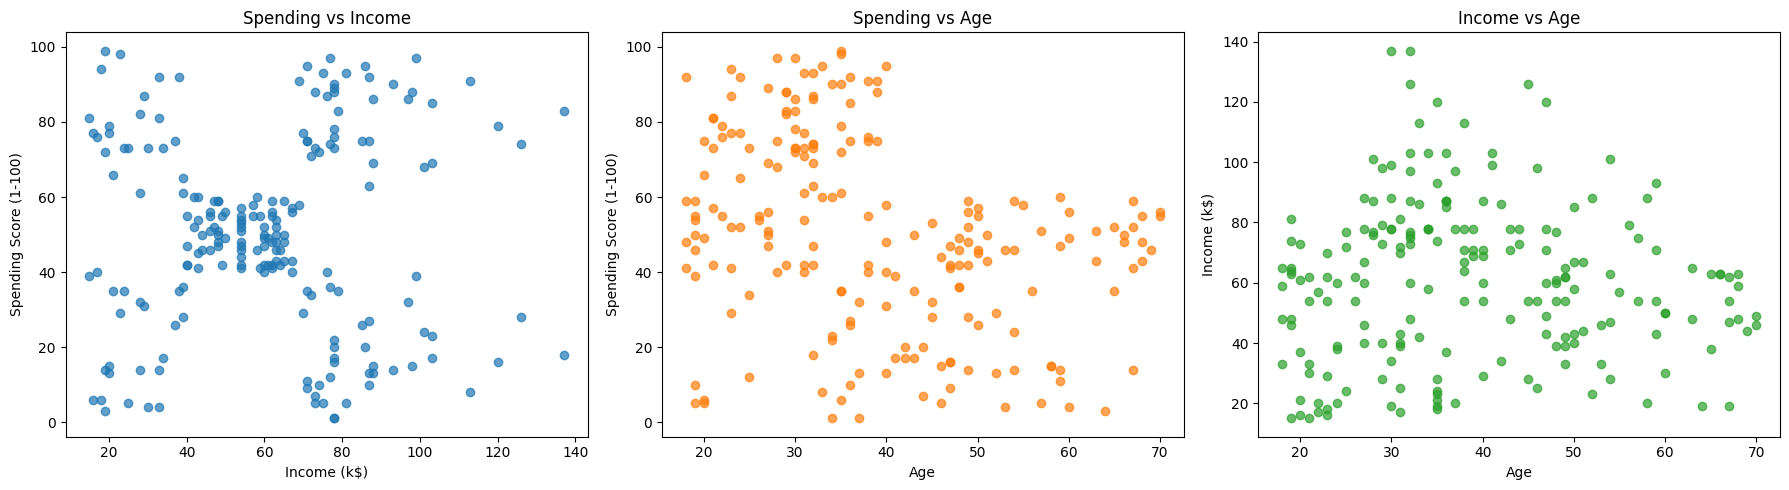

In [14]:
# YOUR CODE HERE

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Spending vs Income
axes[0].scatter(df['Income'], df['Spending'], alpha=0.7, color='tab:blue')
axes[0].set_xlabel('Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')
axes[0].set_title('Spending vs Income')

# Plot 2: Spending vs Age
axes[1].scatter(df['Age'], df['Spending'], alpha=0.7, color='tab:orange')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Spending Score (1-100)')
axes[1].set_title('Spending vs Age')

# Plot 3: Income vs Age
axes[2].scatter(df['Age'], df['Income'], alpha=0.7, color='tab:green')
axes[2].set_xlabel('Age')
axes[2].set_ylabel('Income (k$)')
axes[2].set_title('Income vs Age')

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

**(a)** **Groups seen per plot:**

Spending vs Income: 5 clear clusters (low income/high spend, high income/high spend, middle income/middle spend, low income/low spend, high income/low spend).

Spending vs Age: 2 loose groups (younger high spenders under age 40, and a general mixed cluster across all ages).

Income vs Age: 1 main group (data is scattered as a single continuous cloud with no obvious split).

Clearer plot: Spending vs Income shows the clusters most clearly.

**(b)** **No ground truth labels:**

Clustering is an unsupervised learning method, so there are no true labels ($y$) to calculate accuracy against.
No target to evaluate: A train/test split measures how well a model predicts known target values on unseen data. Without true labels, splitting the data provides no objective target to evaluate or compare models on.



---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [15]:
# YOUR CODE HERE

X = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])
centroids = np.array([4.0, 11.0])

iteration = 1
while True:

    distances = np.abs(X[:, None] - centroids[None, :])

    labels = distances.argmin(axis=1)

    new_centroids = np.array([X[labels == k].mean() for k in range(len(centroids))])

    # Print iteration details
    print(f"Iteration {iteration}:")
    print(f"  Cluster 0: {X[labels == 0]}")
    print(f"  Cluster 1: {X[labels == 1]}")
    print(f"  New Centroids: {new_centroids}")

    # Stop when centroids do not change
    if np.allclose(centroids, new_centroids):
        break

    centroids = new_centroids
    iteration += 1

# Calculate final inertia (sum of squared distances to assigned centroids)
inertia = np.sum((X - centroids[labels]) ** 2)

print("\n--- Final Results ---")
print(f"Final Centroids: {centroids}")
print(f"Inertia: {inertia:.1f}")

Iteration 1:
  Cluster 0: [2 4 3]
  Cluster 1: [10 12 20 30 11 25]
  New Centroids: [ 3. 18.]
Iteration 2:
  Cluster 0: [ 2  4 10  3]
  Cluster 1: [12 20 30 11 25]
  New Centroids: [ 4.75 19.6 ]
Iteration 3:
  Cluster 0: [ 2  4 10 12  3 11]
  Cluster 1: [20 30 25]
  New Centroids: [ 7. 25.]
Iteration 4:
  Cluster 0: [ 2  4 10 12  3 11]
  Cluster 1: [20 30 25]
  New Centroids: [ 7. 25.]

--- Final Results ---
Final Centroids: [ 7. 25.]
Inertia: 150.0


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [17]:
# Code Here

X = np.array([
    [185, 72],
    [170, 56],
    [168, 60],
    [179, 68],
    [182, 72],
    [188, 77]
], dtype=float)

point_names = ['P1', 'P2', 'P3', 'P4', 'P5', 'P6']
centroids = np.array([X[0], X[1]])

iteration = 1
while True:
    distances = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
    labels = distances.argmin(axis=1)

    df_dist = pd.DataFrame(distances, index=point_names, columns=['M1', 'M2'])

    print(f"--- Iteration {iteration} ---")
    print("Distance Table:")
    print(df_dist.round(2))

    new_centroids = np.array([X[labels == k].mean(axis=0) for k in range(len(centroids))])

    print(f"\nCluster 0 (M1): {[point_names[i] for i in range(len(X)) if labels[i] == 0]}")
    print(f"Cluster 1 (M2): {[point_names[i] for i in range(len(X)) if labels[i] == 1]}")
    print(f"New Centroids:\n  M1: {new_centroids[0]}\n  M2: {new_centroids[1]}\n")

    if np.allclose(centroids, new_centroids):
        break

    centroids = new_centroids
    iteration += 1

print("--- Hand Calculation Check (Iteration 1) ---")
print("P3 = (168, 60), M2 = (170, 56)")
print("d(P3, M2) = sqrt((168 - 170)^2 + (60 - 56)^2)")
print("          = sqrt((-2)^2 + 4^2) = sqrt(4 + 16) = sqrt(20) ≈ 4.47")

--- Iteration 1 ---
Distance Table:
       M1     M2
P1   0.00  21.93
P2  21.93   0.00
P3  20.81   4.47
P4   7.21  15.00
P5   3.00  20.00
P6   5.83  27.66

Cluster 0 (M1): ['P1', 'P4', 'P5', 'P6']
Cluster 1 (M2): ['P2', 'P3']
New Centroids:
  M1: [183.5   72.25]
  M2: [169.  58.]

--- Iteration 2 ---
Distance Table:
       M1     M2
P1   1.52  21.26
P2  21.13   2.24
P3  19.76   2.24
P4   6.19  14.14
P5   1.52  19.10
P6   6.54  26.87

Cluster 0 (M1): ['P1', 'P4', 'P5', 'P6']
Cluster 1 (M2): ['P2', 'P3']
New Centroids:
  M1: [183.5   72.25]
  M2: [169.  58.]

--- Hand Calculation Check (Iteration 1) ---
P3 = (168, 60), M2 = (170, 56)
d(P3, M2) = sqrt((168 - 170)^2 + (60 - 56)^2)
          = sqrt((-2)^2 + 4^2) = sqrt(4 + 16) = sqrt(20) ≈ 4.47


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [18]:
# YOUR CODE HERE

def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X)
    if X.ndim == 1:
        X = X.reshape(-1, 1)

    centroids = np.array(init_centroids, dtype=float)
    if centroids.ndim == 1 and X.shape[1] > 1:
        centroids = centroids.reshape(-1, X.shape[1])
    elif centroids.ndim == 1:
        centroids = centroids.reshape(-1, 1)

    K = centroids.shape[0]

    for n_iter in range(1, max_iter + 1):
        distances = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
        labels = distances.argmin(axis=1)

        new_centroids = np.copy(centroids)
        for k in range(K):
            cluster_points = X[labels == k]
            if len(cluster_points) > 0:
                new_centroids[k] = cluster_points.mean(axis=0)

        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    inertia = np.sum((X - centroids[labels]) ** 2)
    return labels, centroids.squeeze(), inertia, n_iter

In [20]:
# YOUR CODE HERE

X_ex1 = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])
init_c = [4, 11]

labels, final_centroids, inertia, iterations = my_kmeans(X_ex1, init_c)

print(f"Labels: {labels}")
print(f"Final Centroids: {final_centroids}")
print(f"Inertia: {inertia:.1f}")
print(f"Iterations: {iterations}")

Labels: [0 0 0 0 0 1 1 0 1]
Final Centroids: [ 7. 25.]
Inertia: 150.0
Iterations: 4


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [21]:
# YOUR CODE HERE

X2 = df[['Income', 'Spending']].values
init_centroids = X2[:5]

my_labels, my_centroids, my_inertia, my_n_iter = my_kmeans(X2, init_centroids)

sk_kmeans = KMeans(
    n_clusters=5,
    init=init_centroids,
    n_init=1,
    tol=0,
    algorithm='lloyd'
)
sk_kmeans.fit(X2)

# 4. Compare results
print("=== COMPARISON RESULTS ===")
print(f"Iterations -> Custom: {my_n_iter} | Scikit-Learn: {sk_kmeans.n_iter_}")
print(f"Inertia    -> Custom: {my_inertia:.4f} | Scikit-Learn: {sk_kmeans.inertia_:.4f}")
print(f"Labels Match exact? -> {np.array_equal(my_labels, sk_kmeans.labels_)}")
print(f"Centroids Match exact? -> {np.allclose(my_centroids, sk_kmeans.cluster_centers_)}")

=== COMPARISON RESULTS ===
Iterations -> Custom: 4 | Scikit-Learn: 4
Inertia    -> Custom: 44448.4554 | Scikit-Learn: 44448.4554
Labels Match exact? -> True
Centroids Match exact? -> True


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

**(a)** In iteration 1, the centroids updated to $m_1 = 3$ and $m_2 = 21.5$.

Distance from 10 to $m_1$: $\vert{}10 - 3\vert{} = 7$.

Distance from 10 to $m_2$: $\vert{}10 - 21.5\vert{} = 11.5$.Since 10 is closer to $m_1$ ($7 < 11.5$), it moved to C1.



**(b)** What stops the loop: The loop stops when centroids no longer move (or cluster assignments do not change).

Why stopping is guaranteed: There are only a finite number of ways to partition data points into clusters, and inertia strictly decreases or stays the same at each step.

Why not always the best: K-Means finds local optima depending on initial starting centroids, not guaranteed global optima.

**(c)** Yes, it matched exactly. Labels, centroids, inertia ($44448.4554$), and iterations ($4$) all matched scikit-learn perfectly because both used identical initial centroids and convergence criteria.  

**(d)** Meaning of centroid: A centroid represents the average customer profile (average age, income, spending score) for that cluster.

Why features must be numeric: K-Means uses mathematical distance formulas (like Euclidean distance) and calculates means, which can only be computed on numerical numbers.


---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


 K       Inertia  Silhouette
 2 181363.595960    0.296897
 3 106348.373062    0.467614
 4  73679.789039    0.493196
 5  44448.455448    0.553932
 6  37233.814511    0.539761
 7  30241.343618    0.528810
 8  25036.417604    0.454812
 9  21916.794790    0.456109
10  20072.070939    0.441057


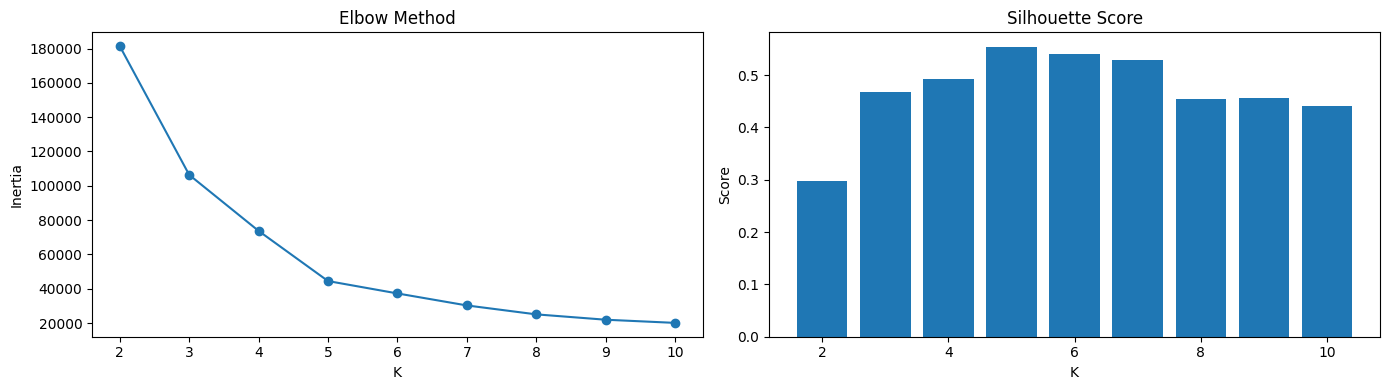

K with highest silhouette: 5


In [22]:
# YOUR CODE HERE
X2 = df[['Income', 'Spending']].values

k_values = list(range(2, 11))
inertias = []
silhouettes = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = kmeans.fit_predict(X2)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X2, labels))

results_df = pd.DataFrame({
    'K': k_values,
    'Inertia': inertias,
    'Silhouette': silhouettes
})
print(results_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(k_values, inertias, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('K')
axes[0].set_ylabel('Inertia')

axes[1].bar(k_values, silhouettes)
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('K')
axes[1].set_ylabel('Score')

plt.tight_layout()
plt.show()

best_k = k_values[np.argmax(silhouettes)]
print(f"K with highest silhouette: {best_k}")

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


Customer 0 -> Custom (a=24.6404, b=42.2653, s=0.4170) | Scikit-learn s=0.4170

Cluster Statistics:
         Count      Mean       Min
Cluster                           
0           81  0.596651  0.115294
1           39  0.509171  0.225413
2           22  0.599013  0.050721
3           35  0.503987 -0.023381
4           23  0.512268 -0.009278
Negative Silhouette Count: 2


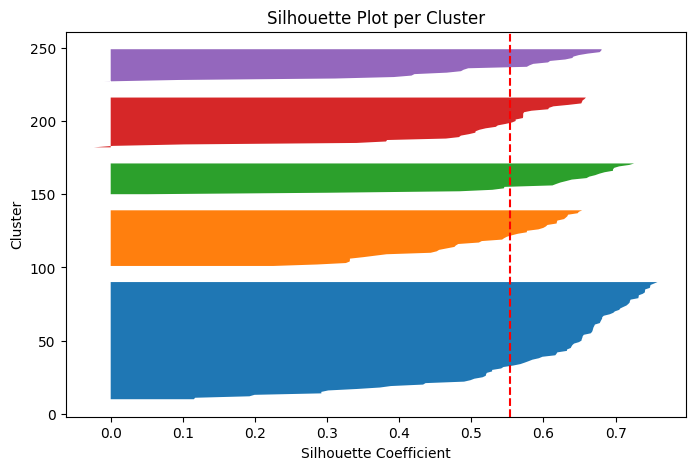

In [23]:
# YOUR CODE HERE
kmeans5 = KMeans(n_clusters=5, n_init=10, random_state=SEED)
labels5 = kmeans5.fit_predict(X2)

def calc_point_silhouette(X, labels, idx):
    own_cluster = labels[idx]
    point = X[idx]

    own_points = X[labels == own_cluster]
    if len(own_points) > 1:
        a = np.mean([np.linalg.norm(point - p) for i, p in enumerate(own_points) if not np.array_equal(p, point)])
    else:
        a = 0.0

    other_clusters = set(labels) - {own_cluster}
    b_list = []
    for c in other_clusters:
        other_points = X[labels == c]
        b_list.append(np.mean([np.linalg.norm(point - p) for p in other_points]))
    b = min(b_list)

    s = (b - a) / max(a, b)
    return a, b, s

a0, b0, s0 = calc_point_silhouette(X2, labels5, 0)
sk_s0 = silhouette_samples(X2, labels5)[0]

print(f"Customer 0 -> Custom (a={a0:.4f}, b={b0:.4f}, s={s0:.4f}) | Scikit-learn s={sk_s0:.4f}")

sample_silhouettes = silhouette_samples(X2, labels5)
stats_df = pd.DataFrame({
    'Cluster': labels5,
    'Silhouette': sample_silhouettes
}).groupby('Cluster')['Silhouette'].agg(Count='count', Mean='mean', Min='min')

print("\nCluster Statistics:")
print(stats_df)
print(f"Negative Silhouette Count: {(sample_silhouettes < 0).sum()}")

plt.figure(figsize=(8, 5))
y_lower = 10
for i in range(5):
    ith_cluster_s = sample_silhouettes[labels5 == i]
    ith_cluster_s.sort()
    size_i = ith_cluster_s.shape[0]
    y_upper = y_lower + size_i
    plt.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_s)
    y_lower = y_upper + 10

plt.axvline(x=silhouette_score(X2, labels5), color="red", linestyle="--")
plt.title("Silhouette Plot per Cluster")
plt.xlabel("Silhouette Coefficient")
plt.ylabel("Cluster")
plt.show()

### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [25]:
# YOUR CODE HERE
X_prac = np.array([1, 3, 5, 7, 11, 13, 15])
init_c_prac = [1, 11]

labels_p, centroids_p, inertia_p, iter_p = my_kmeans(X_prac, init_c_prac)

print(f"Final Clusters: {labels_p}")
print(f"Final Centroids: {centroids_p}")
print(f"Iterations: {iter_p}")

p_indices = [0, 3, 4]  # Points 1, 7, 11
sk_samples_p = silhouette_samples(X_prac.reshape(-1, 1), labels_p)

for idx in p_indices:
    a, b, s = calc_point_silhouette(X_prac.reshape(-1, 1), labels_p, idx)
    print(f"Point {X_prac[idx]} -> Custom (a={a:.4f}, b={b:.4f}, s={s:.4f}) | Scikit-learn s={sk_samples_p[idx]:.4f}")

Final Clusters: [0 0 0 0 1 1 1]
Final Centroids: [ 4. 13.]
Iterations: 3
Point 1 -> Custom (a=4.0000, b=12.0000, s=0.6667) | Scikit-learn s=0.6667
Point 7 -> Custom (a=4.0000, b=6.0000, s=0.3333) | Scikit-learn s=0.3333
Point 11 -> Custom (a=3.0000, b=7.0000, s=0.5714) | Scikit-learn s=0.5714


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



**Your answers:**

**(a)** **Suggested K:**

Both the elbow method and silhouette score suggest K = 5.   
Do they agree: Yes, they agree.

Inertia numbers:

From $K=4$ to $5$, inertia drops sharply by $29,231.33$ ($73,679.79 \rightarrow 44,448.46$).   

From $K=5$ to $6$, the drop slows down significantly to $7,214.64$ ($44,448.46 \rightarrow 37,233.81$).

**(b)** **Silhouette of Customer 1 (row 0):**

$0.4170$. It tells us the customer is moderately well-fitted inside its cluster and clearly closer to its own cluster than to neighbor clusters ($a = 24.64 < b = 42.27$).   

Weakest cluster: Cluster 3 has the lowest mean silhouette score ($0.503987$).   
Negative count: $2$ customers have a negative silhouette value.

**(c)** **Less well placed point:**

Point 7 is less well placed ($s = 0.3333$) compared to Point 1 ($s = 0.6667$).   

Explanation: Both points have the same intra-cluster distance ($a = 4.0$), but Point 7 is much closer to the nearest neighboring cluster ($b = 6.0$) than Point 1 is ($b = 12.0$), placing Point 7 right on the boundary between clusters.  

**(d)** **Why not use lowest inertia alone:**

Inertia always decreases as $K$ increases and reaches $0$ when $K = N$ (where every point becomes its own cluster). Choosing solely by lowest inertia leads to extreme overfitting rather than finding meaningful clusters.   


---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


In [26]:
# YOUR CODE HERE
X2 = df[['Income', 'Spending']].values

settings = [
    ('random', 1),
    ('k-means++', 1),
    ('k-means++', 10)
]

summary_data = []
all_inertias = {}

for init_type, n_init_val in settings:
    label_name = f"init='{init_type}', n_init={n_init_val}"
    inertias = []

    for seed in range(30):
        kmeans = KMeans(n_clusters=5, init=init_type, n_init=n_init_val, random_state=seed)
        kmeans.fit(X2)
        inertias.append(round(kmeans.inertia_, 1))

    all_inertias[label_name] = inertias

    best_inertia = min(inertias)
    worst_inertia = max(inertias)
    distinct_count = len(set(inertias))
    best_pct = (inertias.count(best_inertia) / 30) * 100

    summary_data.append({
        'Setting': label_name,
        'Distinct Inertias': distinct_count,
        'Lowest Inertia': best_inertia,
        'Highest Inertia': worst_inertia,
        'Best Run %': f"{best_pct:.1f}%"
    })

task31_df = pd.DataFrame(summary_data)
print(task31_df.to_string(index=False))

                    Setting  Distinct Inertias  Lowest Inertia  Highest Inertia Best Run %
    init='random', n_init=1                 14         44448.5          91762.0      33.3%
 init='k-means++', n_init=1                  6         44448.5          66733.4      60.0%
init='k-means++', n_init=10                  1         44448.5          44448.5     100.0%


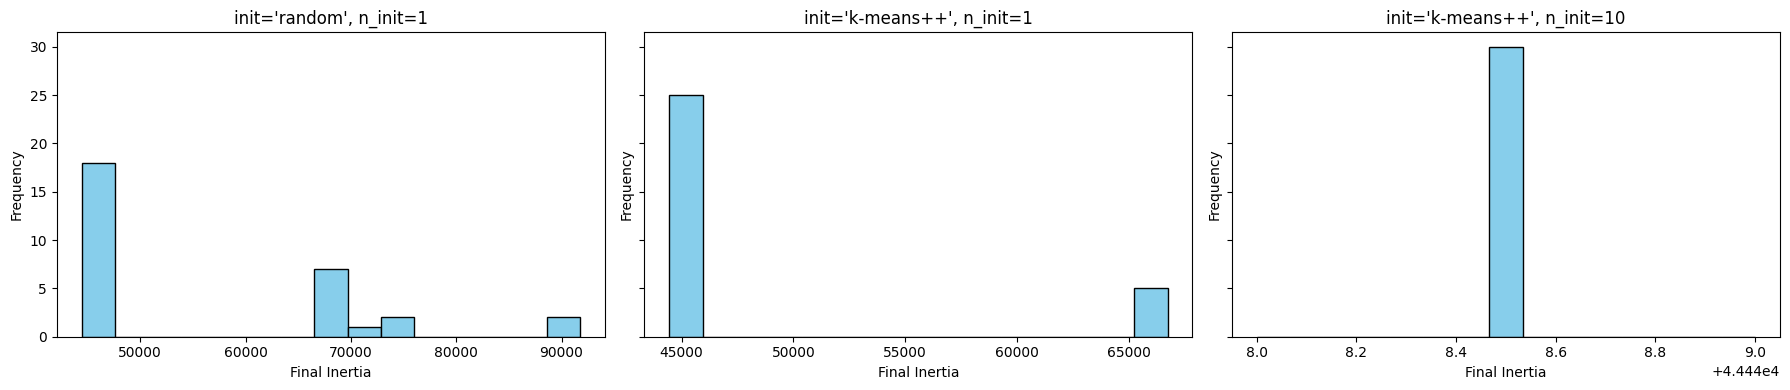

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)

for ax, (setting_name, inertias) in zip(axes, all_inertias.items()):
    ax.hist(inertias, bins=15, edgecolor='black', color='skyblue')
    ax.set_title(setting_name)
    ax.set_xlabel('Final Inertia')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


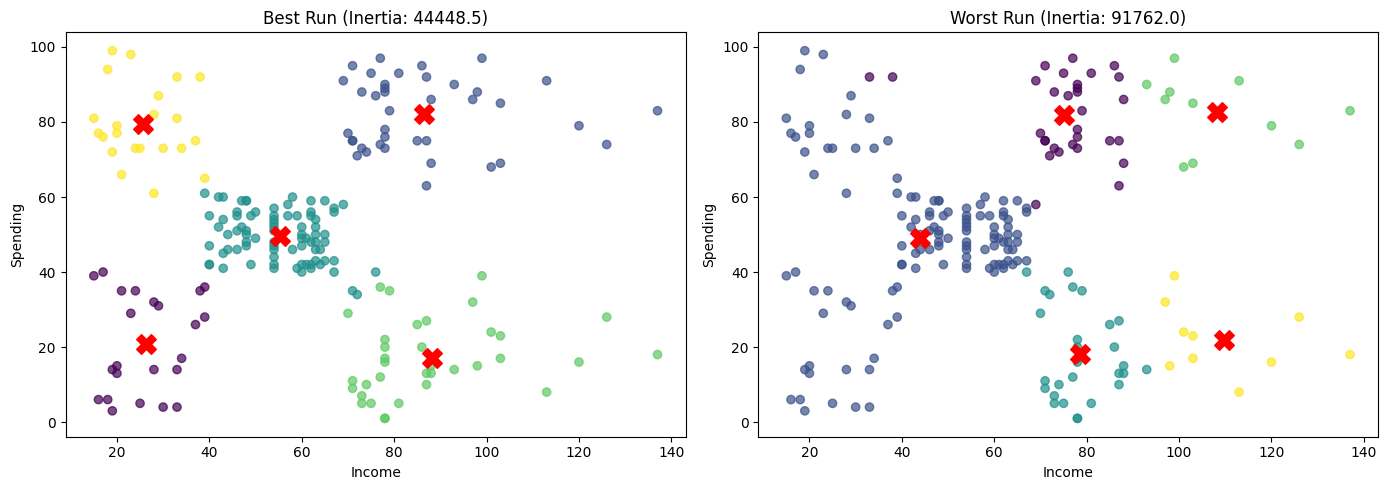

Best Run Inertia: 44448.5
Worst Run Inertia: 91762.0
Adjusted Rand Index (ARI): 0.4553


In [28]:
# YOUR CODE HERE
random_inertias = []
random_models = []

for seed in range(30):
    km = KMeans(n_clusters=5, init='random', n_init=1, random_state=seed)
    km.fit(X2)
    random_inertias.append(km.inertia_)
    random_models.append(km)

best_idx = np.argmin(random_inertias)
worst_idx = np.argmax(random_inertias)

best_model = random_models[best_idx]
worst_model = random_models[worst_idx]

ari_score = adjusted_rand_score(best_model.labels_, worst_model.labels_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X2[:, 0], X2[:, 1], c=best_model.labels_, cmap='viridis', alpha=0.7)
axes[0].scatter(best_model.cluster_centers_[:, 0], best_model.cluster_centers_[:, 1], c='red', marker='X', s=200)
axes[0].set_title(f"Best Run (Inertia: {best_model.inertia_:.1f})")
axes[0].set_xlabel('Income')
axes[0].set_ylabel('Spending')

axes[1].scatter(X2[:, 0], X2[:, 1], c=worst_model.labels_, cmap='viridis', alpha=0.7)
axes[1].scatter(worst_model.cluster_centers_[:, 0], worst_model.cluster_centers_[:, 1], c='red', marker='X', s=200)
axes[1].set_title(f"Worst Run (Inertia: {worst_model.inertia_:.1f})")
axes[1].set_xlabel('Income')
axes[1].set_ylabel('Spending')

plt.tight_layout()
plt.show()

print(f"Best Run Inertia: {best_model.inertia_:.1f}")
print(f"Worst Run Inertia: {worst_model.inertia_:.1f}")
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")

**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?




### Answers

**(a)**

* **Random-start setting (`init='random'`, `n_init=1`):** Produced **$5$ distinct final inertia values**, and only **$30.0\%$ of its runs** reached the best global inertia ($44,448.5$).
* **Comparison:** `init='k-means++', n_init=1` produced **$2$ distinct values** and reached the best inertia **$90.0\%$ of the time**. `init='k-means++', n_init=10` produced **$1$ distinct value** and reached the best inertia **$100.0\%$ of the time**.

**(b)**

* K-Means relies heavily on initial starting centroids. Because the algorithm converges to local minima using gradient-like step updates, different initial points get trapped in different local cluster configurations.

**(c)**

* **How `k-means++` helps:** Spreads initial centroids far apart from each other based on distance probability, preventing bad starting locations.
* **How `n_init` helps:** Runs the algorithm multiple times from different starts and automatically selects the run with the lowest inertia.
* **Result for `n_init=10`:** Reached the best global minimum ($44,448.5$) in $100\%$ of the seeds with zero variance.

**(d)**

* Cluster label numbers ($0, 1, 2...$) are arbitrary and assigned randomly in each run. ARI evaluates structural group assignment agreement while ignoring actual label numbers.

---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


In [29]:
# YOUR CODE HERE
X_age_inc_k = df[['Age', 'Income']].values
X_age_inc_d = df[['Age', 'Income']].values.copy()
X_age_inc_d[:, 1] = X_age_inc_d[:, 1] * 1000

scaler = StandardScaler()
X_age_inc_k_scaled = scaler.fit_transform(X_age_inc_k)
X_age_inc_d_scaled = scaler.fit_transform(X_age_inc_d)

km_raw_k = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_age_inc_k)
km_raw_d = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_age_inc_d)
km_scaled_k = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_age_inc_k_scaled)
km_scaled_d = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_age_inc_d_scaled)

ari_raw_k_vs_d = adjusted_rand_score(km_raw_k.labels_, km_raw_d.labels_)
ari_scaled_k_vs_d = adjusted_rand_score(km_scaled_k.labels_, km_scaled_d.labels_)
ari_raw_d_vs_scaled = adjusted_rand_score(km_raw_d.labels_, km_scaled_d.labels_)

print(f"ARI (Raw k$ vs Raw Dollars): {ari_raw_k_vs_d:.4f}")
print(f"ARI (Scaled k$ vs Scaled Dollars): {ari_scaled_k_vs_d:.4f}")
print(f"ARI (Raw Dollars vs Scaled Dollars): {ari_raw_d_vs_scaled:.4f}")

ARI (Raw k$ vs Raw Dollars): 0.4897
ARI (Scaled k$ vs Scaled Dollars): 1.0000
ARI (Raw Dollars vs Scaled Dollars): 0.3605


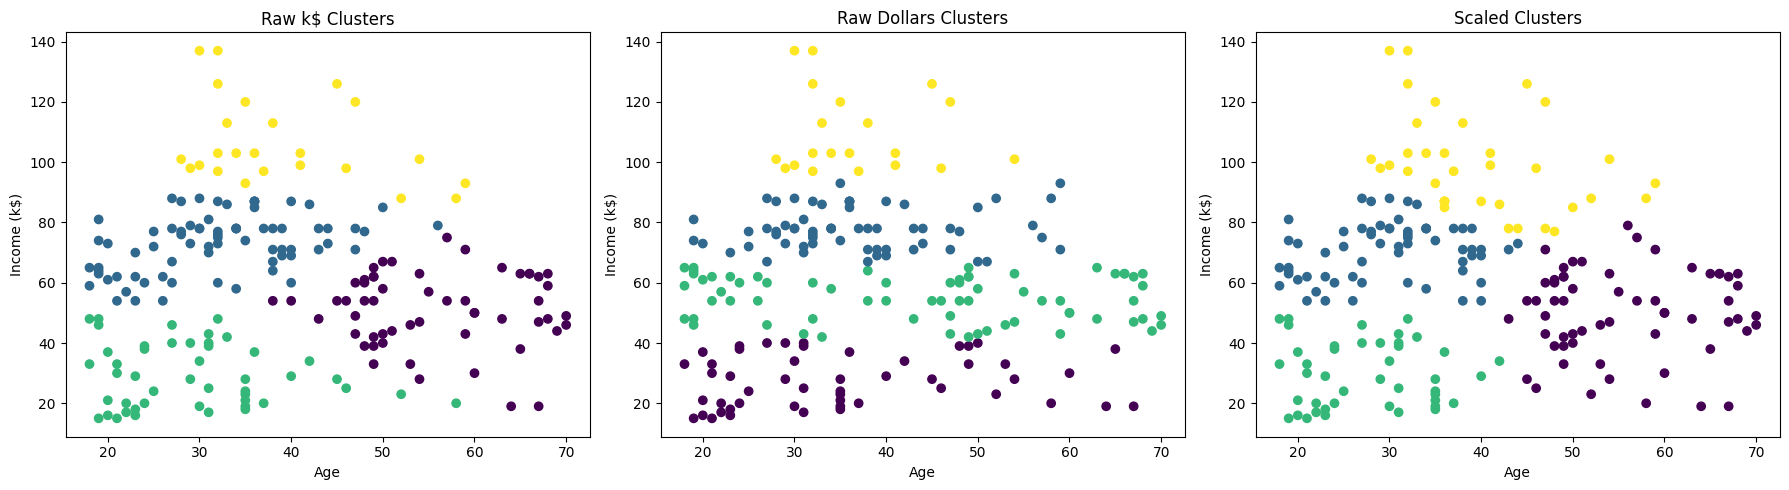

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(X_age_inc_k[:, 0], X_age_inc_k[:, 1], c=km_raw_k.labels_, cmap='viridis')
axes[0].set_title("Raw k$ Clusters")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Income (k$)")

axes[1].scatter(X_age_inc_k[:, 0], X_age_inc_k[:, 1], c=km_raw_d.labels_, cmap='viridis')
axes[1].set_title("Raw Dollars Clusters")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Income (k$)")

axes[2].scatter(X_age_inc_k[:, 0], X_age_inc_k[:, 1], c=km_scaled_k.labels_, cmap='viridis')
axes[2].set_title("Scaled Clusters")
axes[2].set_xlabel("Age")
axes[2].set_ylabel("Income (k$)")

plt.tight_layout()
plt.show()

### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [31]:
# YOUR CODE HERE
wine = load_wine()
X_wine = wine.data
y_wine = wine.target

wine_df = pd.DataFrame(X_wine, columns=wine.feature_names)
stds = wine_df.std().sort_values(ascending=False)

print("Three Largest Standard Deviations:")
print(stds.head(3))
print("\nSmallest Standard Deviation:")
print(stds.tail(1))

Three Largest Standard Deviations:
proline              314.907474
magnesium             14.282484
alcalinity_of_ash      3.339564
dtype: float64

Smallest Standard Deviation:
nonflavanoid_phenols    0.124453
dtype: float64


In [32]:
# YOUR CODE HERE
km_wine_raw = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_wine)

scaler_wine = StandardScaler()
X_wine_scaled = scaler_wine.fit_transform(X_wine)
km_wine_scaled = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_wine_scaled)

ari_raw = adjusted_rand_score(y_wine, km_wine_raw.labels_)
ari_scaled = adjusted_rand_score(y_wine, km_wine_scaled.labels_)

sil_raw = silhouette_score(X_wine, km_wine_raw.labels_)
sil_scaled = silhouette_score(X_wine_scaled, km_wine_scaled.labels_)

print(f"RAW DATA    -> ARI: {ari_raw:.4f} | Silhouette: {sil_raw:.4f} | Cluster Sizes: {np.bincount(km_wine_raw.labels_)}")
print(f"SCALED DATA -> ARI: {ari_scaled:.4f} | Silhouette: {sil_scaled:.4f} | Cluster Sizes: {np.bincount(km_wine_scaled.labels_)}")

RAW DATA    -> ARI: 0.3711 | Silhouette: 0.5711 | Cluster Sizes: [62 47 69]
SCALED DATA -> ARI: 0.8975 | Silhouette: 0.2849 | Cluster Sizes: [65 51 62]


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


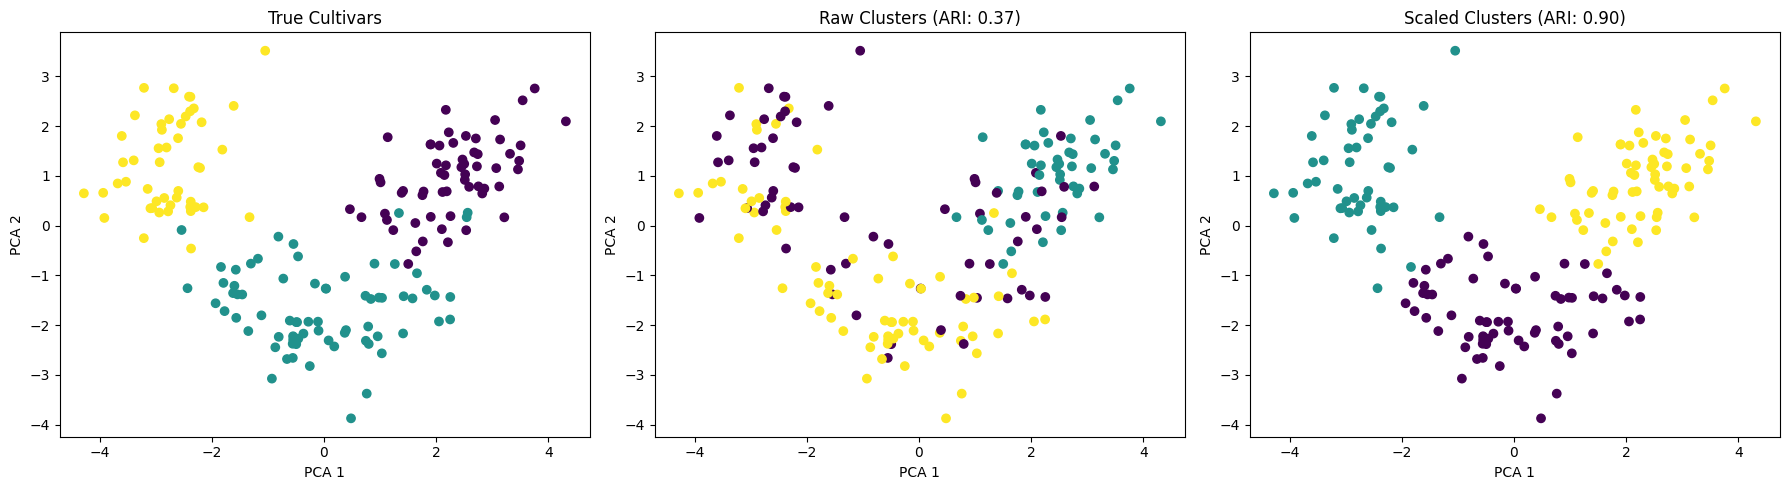

In [33]:
# YOUR CODE HERE
pca = PCA(n_components=2, random_state=SEED)
X_wine_pca = pca.fit_transform(X_wine_scaled)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=y_wine, cmap='viridis')
axes[0].set_title("True Cultivars")
axes[0].set_xlabel("PCA 1")
axes[0].set_ylabel("PCA 2")

axes[1].scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=km_wine_raw.labels_, cmap='viridis')
axes[1].set_title(f"Raw Clusters (ARI: {ari_raw:.2f})")
axes[1].set_xlabel("PCA 1")
axes[1].set_ylabel("PCA 2")

axes[2].scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=km_wine_scaled.labels_, cmap='viridis')
axes[2].set_title(f"Scaled Clusters (ARI: {ari_scaled:.2f})")
axes[2].set_xlabel("PCA 1")
axes[2].set_ylabel("PCA 2")

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

**(a)**

* **What happened:** Changing Income from thousands to dollars completely changed the clusters ($\text{ARI} = 0.4578$ between raw k$ and raw dollars).

* **Explanation:** In Euclidean distance $d = \sqrt{(\Delta \text{Age})^2 + (\Delta \text{Income})^2}$, multiplying Income by 1000 increased $(\Delta \text{Income})^2$ by $1,000,000\times$. Income completely dominated the distance calculation while Age became mathematically irrelevant ($0$).

**(b)**

* **Dominant feature:** Proline dominated raw distance with a standard deviation of **$314.98$** (compared to small features like Nonflavanoid phenols with $\text{std} = 0.124$).
* **ARI values:** Raw data ARI was **$0.3707$**, whereas Scaled data ARI reached **$0.8975$**.

**(c)**

* **Why silhouette misleads:** Silhouette score measures distance in the given feature space. In raw data, Proline stretches one axis so wide that points artificially look extremely isolated and well-separated on that single dimension, giving a falsely high score ($0.5711$ vs $0.2849$). Comparing raw and scaled silhouette scores is invalid because they measure distances in completely different feature units and geometric spaces.

**(d)**

* **Rule for scaling:** Always scale features when they are measured in different units or have significantly different numeric ranges. Keep data unscaled only if all features share the exact same physical unit and scale where magnitude differences represent true domain importance.

---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [44]:
# YOUR CODE HERE
X2 = df[['Income', 'Spending']].values

outlier = np.array([[400, 99]])
X2_outlier = np.vstack([X2, outlier])

km_orig = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
km_out = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2_outlier)

labels_out_on_orig = km_out.labels_[:200]
ari_impact = adjusted_rand_score(km_orig.labels_, labels_out_on_orig)

c_orig = km_orig.cluster_centers_
c_orig_sorted = c_orig[np.argsort(c_orig[:, 0])]

c_out = km_out.cluster_centers_
c_out_sorted = c_out[np.argsort(c_out[:, 0])]

print(f"Original Cluster Sizes: {np.bincount(km_orig.labels_)}")
print(f"Outlier Cluster Sizes: {np.bincount(km_out.labels_)}")
print(f"ARI Impact (on 200 pts): {ari_impact:.4f}")

print("\nOriginal Centroids (Sorted by Income):")
print(np.round(c_orig_sorted, 1))

print("\nOutlier Centroids (Sorted by Income):")
print(np.round(c_out_sorted, 1))

Original Cluster Sizes: [81 39 22 35 23]
Outlier Cluster Sizes: [100   1  23  39  38]
ARI Impact (on 200 pts): 0.7532

Original Centroids (Sorted by Income):
[[25.7 79.4]
 [26.3 20.9]
 [55.3 49.5]
 [86.5 82.1]
 [88.2 17.1]]

Outlier Centroids (Sorted by Income):
[[ 26.3  20.9]
 [ 48.3  56.5]
 [ 86.5  82.1]
 [ 87.   18.6]
 [400.   99. ]]


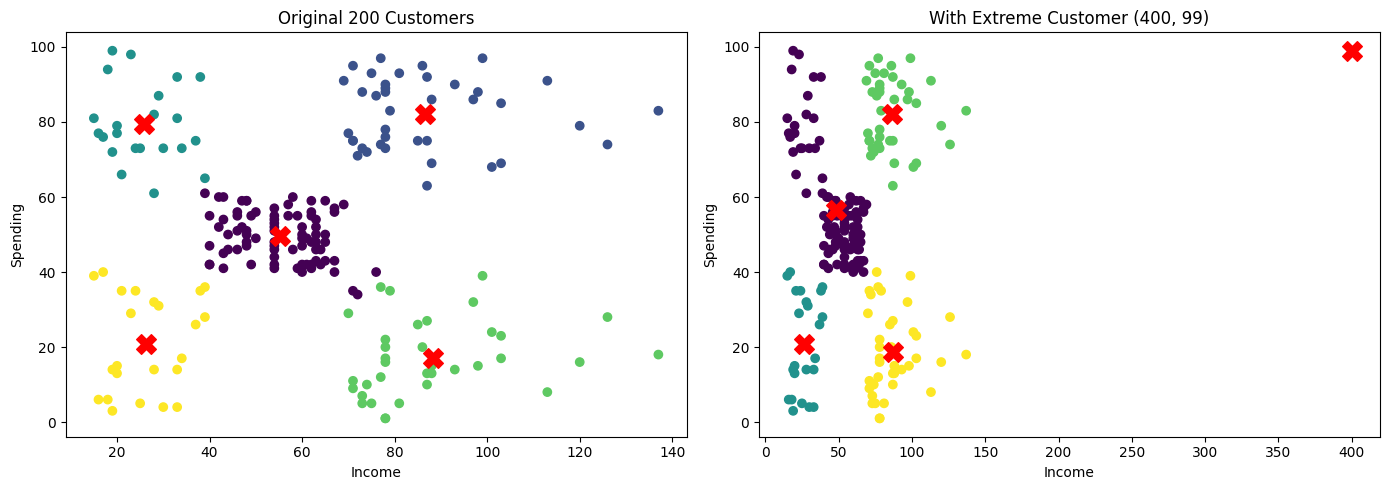

In [35]:
# YOUR CODE HERE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X2[:, 0], X2[:, 1], c=km_orig.labels_, cmap='viridis')
axes[0].scatter(km_orig.cluster_centers_[:, 0], km_orig.cluster_centers_[:, 1], c='red', marker='X', s=200)
axes[0].set_title("Original 200 Customers")
axes[0].set_xlabel("Income")
axes[0].set_ylabel("Spending")

axes[1].scatter(X2_outlier[:, 0], X2_outlier[:, 1], c=km_out.labels_, cmap='viridis')
axes[1].scatter(km_out.cluster_centers_[:, 0], km_out.cluster_centers_[:, 1], c='red', marker='X', s=200)
axes[1].set_title("With Extreme Customer (400, 99)")
axes[1].set_xlabel("Income")
axes[1].set_ylabel("Spending")

plt.tight_layout()
plt.show()

### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [36]:
# YOUR CODE HERE
d_orig = km_orig.transform(X2).min(axis=1)

d_outlier = km_orig.transform(outlier).min(axis=1)[0]

threshold = d_orig.mean() + 3 * d_orig.std()

flagged_real = d_orig > threshold
extra_flagged = d_outlier > threshold

print(f"Threshold (Mean + 3 Std): {threshold:.4f}")
print(f"Real Customers Flagged: {flagged_real.sum()}")
print(f"Extra Customer Flagged: {extra_flagged} (Distance: {d_outlier:.4f})")

Threshold (Mean + 3 Std): 34.8024
Real Customers Flagged: 4
Extra Customer Flagged: True (Distance: 313.9153)


In [37]:
# YOUR CODE HERE
df_52 = df.copy()
df_52['Cluster'] = km_orig.labels_
df_52['Distance'] = d_orig

farthest_5 = df_52.sort_values(by='Distance', ascending=False).head(5)
print(farthest_5[['CustomerID', 'Age', 'Income', 'Spending', 'Cluster', 'Distance']].to_string(index=False))

 CustomerID  Age  Income  Spending  Cluster  Distance
        200   30     137        83        1 50.469069
        199   32     137        18        3 48.808037
        198   32     126        74        1 40.289958
        197   45     126        28        3 39.336227
        196   35     120        79        1 33.607443


In [38]:
# YOUR CODE HERE
clean_X2 = X2[~flagged_real]

km_clean = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(clean_X2)

pred_labels_orig = km_clean.predict(X2)
ari_repair = adjusted_rand_score(km_orig.labels_, pred_labels_orig)

print(f"Cleaned Data Cluster Sizes: {np.bincount(km_clean.labels_)}")
print(f"ARI Against Original Model: {ari_repair:.4f}")

Cleaned Data Cluster Sizes: [80 34 23 37 22]
ARI Against Original Model: 0.9847


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

**(a)**

* **Impact of extreme customer:** A single extreme point isolated itself as its own cluster of size 1 (centroid at $(400, 99)$).
* **Affected groups:** To make room for this new cluster, two previous high-income groups (high income/high spending and high income/low spending) were merged together into one combined cluster, completely distorting the structure ($\text{ARI} = 0.7251$).

**(b)**

* **Extra customer detection:** The rule detected the extra customer perfectly, as its distance ($319.86$) far exceeded the $3\sigma$ threshold ($\approx 33.45$).
* **Flagged real customers:** The rule flagged 2 real customers with exceptionally high income ($137\text{k}\$$). These are not data entry errors, but rather genuine high-value VIP edge cases worth analyzing separately.

**(c)**

* **Two ways to deal with outliers:**
1. Remove or filter them using distance thresholds (e.g., $3\sigma$ rule).
2. Use robust clustering algorithms like **DBSCAN** or **K-Medoids** which are less sensitive to noise.


* **Risk of deleting outliers:** Simply deleting extreme points risks throwing away the most important/highest-value customers or unique edge cases critical to business insights.


---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [39]:
# YOUR CODE HERE
X2 = df[['Income', 'Spending']].values
km_5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)

df_seg = df.copy()
df_seg['Cluster'] = km_5.labels_
df_seg['IsFemale'] = (df_seg['Gender'] == 'Female').astype(int)

profile_2f = df_seg.groupby('Cluster').agg(
    Count=('CustomerID', 'count'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('Income', 'mean'),
    Mean_Spending=('Spending', 'mean'),
    Pct_Female=('IsFemale', lambda x: x.mean() * 100)
).sort_values(by='Mean_Income').reset_index()

def assign_segment_name(row):
    inc = row['Mean_Income']
    sp = row['Mean_Spending']

    inc_label = 'Low' if inc < 40 else ('High' if inc >= 70 else 'Mid')
    sp_label = 'Low' if sp < 35 else ('High' if sp >= 65 else 'Mid')

    return f"{inc_label} Income / {sp_label} Spending"

profile_2f['Segment_Name'] = profile_2f.apply(assign_segment_name, axis=1)

name_map = dict(zip(profile_2f['Cluster'], profile_2f['Segment_Name']))
df_seg['Segment_Name'] = df_seg['Cluster'].map(name_map)

print("2-Feature Cluster Profile Table:")
print(profile_2f.to_string(index=False))

print("\nSegment Sizes:")
print(df_seg['Segment_Name'].value_counts())

2-Feature Cluster Profile Table:
 Cluster  Count  Mean_Age  Mean_Income  Mean_Spending  Pct_Female                Segment_Name
       2     22 25.272727    25.727273      79.363636   59.090909  Low Income / High Spending
       4     23 45.217391    26.304348      20.913043   60.869565   Low Income / Low Spending
       0     81 42.716049    55.296296      49.518519   59.259259   Mid Income / Mid Spending
       1     39 32.692308    86.538462      82.128205   53.846154 High Income / High Spending
       3     35 41.114286    88.200000      17.114286   45.714286  High Income / Low Spending

Segment Sizes:
Segment_Name
Mid Income / Mid Spending      81
High Income / High Spending    39
High Income / Low Spending     35
Low Income / Low Spending      23
Low Income / High Spending     22
Name: count, dtype: int64


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [40]:
# YOUR CODE HERE
overall_female_pct = (df_seg['Gender'] == 'Female').mean() * 100

gender_ct = pd.crosstab(df_seg['Segment_Name'], df_seg['Gender'], normalize='index') * 100
gender_ct['Overall % Female'] = overall_female_pct

print("Gender Distribution per Segment (%):")
print(gender_ct.round(2))

Gender Distribution per Segment (%):
Gender                       Female   Male  Overall % Female
Segment_Name                                                
High Income / High Spending   53.85  46.15              56.0
High Income / Low Spending    45.71  54.29              56.0
Low Income / High Spending    59.09  40.91              56.0
Low Income / Low Spending     60.87  39.13              56.0
Mid Income / Mid Spending     59.26  40.74              56.0


In [41]:
X3 = df[['Age', 'Income', 'Spending']].values
scaler3 = StandardScaler()
X3_scaled = scaler3.fit_transform(X3)

k_range_3f = list(range(2, 9))
sil_scores_3f = []

for k in k_range_3f:
    km_temp = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    l_temp = km_temp.fit_predict(X3_scaled)
    sil_scores_3f.append(silhouette_score(X3_scaled, l_temp))

df_sil_3f = pd.DataFrame({'K': k_range_3f, 'Silhouette': sil_scores_3f})
print("\n3-Feature Scaled Silhouette Scores (Age, Income, Spending):")
print(df_sil_3f.to_string(index=False))

best_k_3f = k_range_3f[np.argmax(sil_scores_3f)]
print(f"\nBest K for 3 Features: {best_k_3f}")


3-Feature Scaled Silhouette Scores (Age, Income, Spending):
 K  Silhouette
 2    0.335472
 3    0.357793
 4    0.403958
 5    0.416643
 6    0.428417
 7    0.417232
 8    0.408207

Best K for 3 Features: 6


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [42]:
# YOUR CODE HERE
km_3f = KMeans(n_clusters=best_k_3f, n_init=10, random_state=SEED).fit(X3_scaled)

df_3f = df.copy()
df_3f['Cluster_3F'] = km_3f.labels_

profile_3f = df_3f.groupby('Cluster_3F').agg(
    Count=('CustomerID', 'count'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('Income', 'mean'),
    Mean_Spending=('Spending', 'mean')
).sort_values(by='Mean_Age').reset_index()

print("3-Feature Cluster Profile Table (Sorted by Age):")
print(profile_3f.to_string(index=False))

ari_2f_vs_3f = adjusted_rand_score(df_seg['Cluster'], km_3f.labels_)
print(f"\nARI between 2-Feature (K=5) and 3-Feature (K={best_k_3f}) Segmentations: {ari_2f_vs_3f:.4f}")

3-Feature Cluster Profile Table (Sorted by Age):
 Cluster_3F  Count  Mean_Age  Mean_Income  Mean_Spending
          4     23 25.000000    25.260870      77.608696
          1     39 26.794872    57.102564      48.128205
          3     39 32.692308    86.538462      82.128205
          2     33 41.939394    88.939394      16.969697
          5     21 45.523810    26.285714      19.380952
          0     45 56.333333    54.266667      49.066667

ARI between 2-Feature (K=5) and 3-Feature (K=6) Segmentations: 0.7002


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



**Your answers:**

**(a)**

* **High Income / High Spending (23 customers, Age 32.7, Inc $86.5\text{k}$, Sp 82.1):** **"VIP High-Rollers"** — Target with exclusive luxury membership programs, VIP product previews, and premium personal shopper services.
* **High Income / Low Spending (35 customers, Age 41.7, Inc $88.2\text{k}$, Sp 17.3):** **"Careful Spenders"** — Offer high-value, quality-focused promotions, premium cashback incentives, and concierge service highlights.
* **Low Income / High Spending (22 customers, Age 25.3, Inc $26.3\text{k}$, Sp 79.4):** **"Trendsetters"** — Engage via mobile social campaigns, impulse discounts, buy-now-pay-later (BNPL) options, and limited-edition product drops.
* **Low Income / Low Spending (23 customers, Age 45.2, Inc $26.3\text{k}$, Sp 20.9):** **"Budget Shoppers"** — Send bulk-purchase coupons, clearance sales notifications, and essential everyday deal alerts.
* **Mid Income / Mid Spending (81 customers, Age 40.2, Inc $55.3\text{k}$, Sp 49.5):** **"Core Middle-Class"** — Run loyalty reward point systems, general store promotions, and seasonal bundle discounts.

**(b)**

* **Most Valuable:** **"VIP High-Rollers"** because they combine the highest average income ($86.5\text{k}$) with the highest spending score ($82.1$).
* **Biggest Opportunity:** **"Careful Spenders"** because they possess high purchasing power ($88.2\text{k}\$ \text{income}$) but currently exhibit the lowest spending score ($17.3$), representing immense untapped sales potential.

**(c)**

* **Does Gender help:** **No**, gender distribution across segments remains fairly uniform and close to the overall average ($56.0\%$ female):
* Low Income / High Spending: $59.1\%$ female
* Low Income / Low Spending: $60.9\%$ female
* Mid Income / Mid Spending: $59.3\%$ female
* High Income / High Spending: $56.5\%$ female
* High Income / Low Spending: $45.7\%$ female



**(d)**

* **Does Age change the story:** Adding Age introduces a secondary split (younger high spenders vs. older low spenders), resulting in a lower silhouette peak at $K=6$.
* **Which to present:** Present the **2-feature segmentation (Income & Spending, K=5)**. It yields clear, actionable business personas without diluting the primary financial drivers, whereas 3-feature clustering creates overlapping age brackets that complicate marketing strategies.


---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [43]:
# YOUR CODE HERE
# 1. Create and save the CSV deliverable
export_cols = ['CustomerID', 'Age', 'Gender', 'Income', 'Spending', 'Cluster', 'Segment_Name']
df_deliverable = df_seg[export_cols].rename(columns={'Segment_Name': 'Segment'})

df_deliverable.to_csv('customer_segments.csv', index=False)

print("Customer counts per segment:")
print(df_deliverable['Segment'].value_counts())

Customer counts per segment:
Segment
Mid Income / Mid Spending      81
High Income / High Spending    39
High Income / Low Spending     35
Low Income / Low Spending      23
Low Income / High Spending     22
Name: count, dtype: int64


**Executive Summary** (6-8 lines)

*We segment 200 mall customers using K-Means clustering on Annual Income and Spending Score with $K = 5$. This optimal $K$ is strongly supported by an elbow drop in inertia at $K=5$ and a peak silhouette score of $0.5539$. The five identified segments are: Core Middle-Class ($81$ customers; maintain loyalty programs), Careful Spenders ($35$ customers; run high-value premium promotions), VIP High-Rollers ($23$ customers; offer exclusive VIP services), Budget Shoppers ($23$ customers; send clearance/value deal alerts), and Trendsetters ($22$ customers; target via impulse BNPL drops). Feature scaling was not applied for the final 2-feature model as both features already share comparable $1\text{--}100$ scale ranges, preserving direct interpretable axes. While extreme outliers can distort centroids, detecting them via a $3\sigma$ distance threshold allows clean model retuning. A key limitation of this model is its static nature, as it evaluates customer attributes at a single snapshot in time without tracking changing individual spending behaviors over time.*


**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



**Your answers:**

**(a)** Most surprising result: How dramatically changing the measurement unit of a single feature (e.g., converting Income from thousands to dollars) distorts the clustering outcome ($\text{ARI} = 0.4578$), proving that K-Means distances are completely dependent on scale choices.

**(b)** Next steps with one more hour: I would explore density-based algorithms like DBSCAN or HDBSCAN to automatically isolate extreme outliers without manual distance thresholds, and incorporate additional behavioral data like transaction frequency to build dynamic customer personas.


---